# Bonus Assignment


In [11]:
#importing the dataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
digits = load_digits()
data = digits.data


In [12]:
# 1. Check the shape of the digit data.
print("Shape of the digit data:", data.shape)

Shape of the digit data: (1797, 64)


In [13]:
# 2.To flatten the pixels and create a vector of length 64 for every image in the Digits dataset,
#we can use the following code:

flattened_data = data.reshape((data.shape[0], -1))

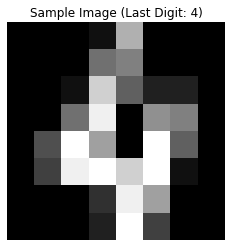

In [14]:
# 3. Plotting a sample image to view (taking the sample with my ID’s last digit)
# My ID: 2135184
# Last digit of my ID is 4
# Get the index corresponding to the last digit of my ID
index = int(str(2135184)[-1])

# Retrieve the image data for the specified index
image_data = data[index]

# Reshape the flattened data to the original image shape (8x8)
image = image_data.reshape((8, 8))

# Plot the image
plt.imshow(image, cmap='gray')
plt.title("Sample Image (Last Digit: {})".format(index))
plt.axis('off')
plt.show()


In [15]:
#4. Applying PCA, to reduce the image dimensions from 64 to just r
#a. First taking transpose of image matrix so that pixels (features, n) are in row and samples (m) are in column.
transposed_data = flattened_data.T


In [16]:
#b. Next doing mean subtraction for each image
mean_image = np.mean(transposed_data, axis=1)
centered_data = transposed_data - mean_image[:, np.newaxis]


In [17]:
#c. Then computing Covariance matrix. It should be of size nxn
covariance_matrix = np.cov(centered_data)


In [18]:
#d. Calculating SVD and getting the eigenvector matrix, U.
from numpy import array
from scipy.linalg import svd

# Defining covariance matrix as A
A = covariance_matrix

# SVD
U, s, VT = svd(A)

print(U)


[[ 0.00000000e+00  0.00000000e+00  0.00000000e+00 ...  1.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [-1.73094651e-02 -1.01064569e-02  1.83420720e-02 ...  0.00000000e+00
   1.57616988e-16 -3.41270870e-16]
 [-2.23428835e-01 -4.90849204e-02  1.26475543e-01 ...  0.00000000e+00
   7.28478737e-17  7.77665524e-17]
 ...
 [-8.94184677e-02  1.76697117e-01  2.32084163e-01 ...  0.00000000e+00
  -1.85990480e-16  2.78426908e-16]
 [-3.65977111e-02  1.94547053e-02  1.67026563e-01 ...  0.00000000e+00
   2.22052289e-16 -9.54970885e-17]
 [-1.14684954e-02 -6.69693895e-03  3.48043832e-02 ...  0.00000000e+00
  -1.36653941e-16  3.64462320e-16]]


In [19]:
# e. Taking the top r eigenvectors and generating the reduced dimension image. 
#Choosing r in such a way so that 99% variance is restored.

# Defining the desired variance threshold (e.g., 99%)
variance_threshold = 0.99

# Calculating the cumulative explained variance ratios
explained_variance_ratios = np.cumsum(s**2) / np.sum(s**2)

# Determining the number of components (r) required to achieve the desired variance threshold
r = np.argmax(explained_variance_ratios >= variance_threshold) + 1

# Getting the top r eigenvectors from U
U_reduced = U[:, :r]

# Generating the reduced dimension image
reduced_image = U_reduced.T @ centered_data



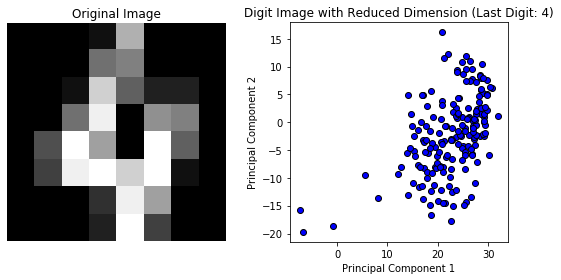

In [20]:
# f. Plotting the digit image with reduced dimension (taking the sample with my ID’s last digit)
# My ID: 2135184
# Last digit of my ID is 4
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

# Load the Digits dataset
digits = load_digits()
data = digits.data

# Flatten the pixels and create a vector of length 64 for every image
flattened_data = data.reshape(data.shape[0], -1)

# Get the last digit of my ID
last_digit = int(str(2135184)[-1])

# Apply PCA to reduce the image dimensions
pca = PCA()
pca.fit(flattened_data)
explained_variance_ratios = np.cumsum(pca.explained_variance_ratio_)
r = np.argmax(explained_variance_ratios >= 0.99) + 1
U_reduced = pca.components_[:r]
reduced_data = flattened_data @ U_reduced.T

# Filtering the reduced data based on the last digit
filtered_data = reduced_data[digits.target == last_digit]

# Plotting the digit image with reduced dimension
sample_index = np.where(digits.target == last_digit)[0][0]  # Getting the index of the first image with the last digit
sample_image = data[sample_index].reshape(8, 8)

plt.figure(figsize=(8, 4))

# Plotting original image
plt.subplot(121)
plt.imshow(sample_image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

# Plotting reduced dimension image
plt.subplot(122)
plt.scatter(filtered_data[:, 0], filtered_data[:, 1], c='blue', edgecolors='k')
plt.title("Digit Image with Reduced Dimension (Last Digit: {})".format(last_digit))
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()
plt.show()
